# Test Case 1 — Publication post-processing

Python/Jupyter conversion of `POST_TC1_ADVECTION_PUBLICATION_2x4.m`, using the same frozen KAPI-ELM publication style module as the other test cases.

This post-processing notebook uses the two-Gaussian advection test case with pulse centers at $x=-0.4$ and $x=0.4$ and the corresponding Stage 1/Stage 2 result files.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from kapi_onet_publication_style import (
    DOUBLE_COLUMN_WIDTH, BLUE, VERMILLION, CMAP_MAGNITUDE,
    add_major_y_grid, format_colorbar, save_figure
)

In [2]:
f1=Path("STAGE_01_CFKS_ADV_TWO_GAUSSIANS_attention.npz")
f2=Path("STAGE_02_CFKS_ADV_TWO_GAUSSIANS_results.npz")
if not f1.exists(): raise FileNotFoundError("Run Stage 1 first.")
if not f2.exists(): raise FileNotFoundError("Run Stage 2 first.")
P=np.load(f1,allow_pickle=False)
C=np.load(f2,allow_pickle=False)

tol=1e-14
if abs(float(P["sigma_x"])-float(C["sigma_x"]))>tol or abs(float(P["sigma_t"])-float(C["sigma_t"]))>tol:
    raise ValueError("Predictor/corrector kernel scales do not match.")
if float(P["pulse_beta"])!=float(C["pulse_beta"]) or int(P["NBx"])!=int(C["NBx"]):
    raise ValueError("Predictor/corrector problem definitions do not match.")

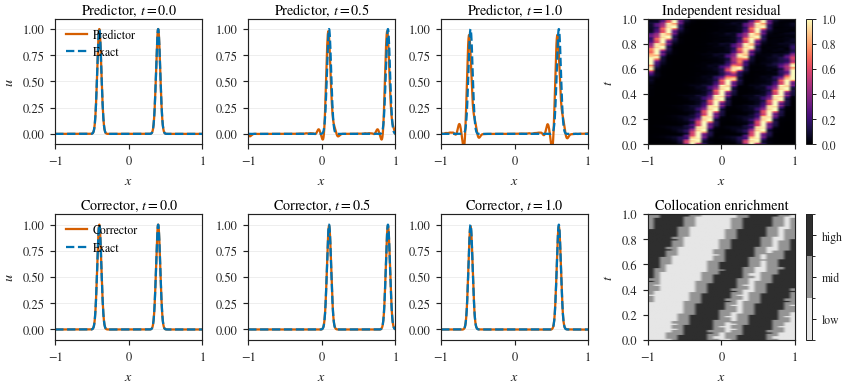

Saved:
  TC1_Advection_2x4.pdf
  TC1_Advection_2x4.png


In [3]:
XL,XR,L=map(float,(P["XL"],P["XR"],P["L"]))
pulse_beta=float(P["pulse_beta"])
pulse_centers=P["pulse_centers"].astype(float)
x=P["x_plot"]
t_snap=np.array([0.0,0.5,1.0])

def init(xx):
    xx = np.asarray(xx, float)
    return (
        np.exp(-(pulse_beta*(xx-pulse_centers[0]))**2)
        + np.exp(-(pulse_beta*(xx-pulse_centers[1]))**2)
    )

def uexact(xx, tt):
    xx = np.asarray(xx, float)
    xshift = np.mod(xx - tt - XL, L) + XL
    return init(xshift)
idxP=np.array([np.argmin(np.abs(P["plot_times"]-t)) for t in t_snap])
idxC=np.array([np.argmin(np.abs(C["plot_times"]-t)) for t in t_snap])
t_used=P["plot_times"][idxP]
U_pred_snap=P["Uplot"][idxP].T
U_corr_snap=C["Uplot"][idxC].T
U_ex_snap=np.column_stack([uexact(x,t) for t in t_used])

Rmat=P["Rmat"]
Lmat=P["Lmat"]
x_edges=P["x_edges"]
nSlabs=int(P["nSlabs"]); dt_slab=float(P["dt_slab"])

fig,axes=plt.subplots(2,4,figsize=(DOUBLE_COLUMN_WIDTH,DOUBLE_COLUMN_WIDTH*0.46),constrained_layout=True)

for k in range(3):
    ax=axes[0,k]
    ax.plot(x,U_pred_snap[:,k],color=VERMILLION,label="Predictor")
    ax.plot(x,U_ex_snap[:,k],"--",color=BLUE,label="Exact")
    ax.set_xlim(XL,XR); ax.set_ylim(-0.10,1.10)
    ax.set_xlabel(r"$x$")
    if k==0:
        ax.set_ylabel(r"$u$"); ax.legend(loc="upper left")
    ax.set_title(rf"Predictor, $t={t_used[k]:.1f}$")
    add_major_y_grid(ax)

ax=axes[0,3]
im=ax.imshow(Rmat,origin="lower",aspect="auto",
             extent=[x_edges[0],x_edges[-1],0,nSlabs*dt_slab],
             vmin=0,vmax=1,cmap=CMAP_MAGNITUDE)
ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$t$"); ax.set_title("Independent residual")
cb=fig.colorbar(im,ax=ax); format_colorbar(cb)

for k in range(3):
    ax=axes[1,k]
    ax.plot(x,U_corr_snap[:,k],color=VERMILLION,label="Corrector")
    ax.plot(x,U_ex_snap[:,k],"--",color=BLUE,label="Exact")
    ax.set_xlim(XL,XR); ax.set_ylim(-0.10,1.10)
    ax.set_xlabel(r"$x$")
    if k==0:
        ax.set_ylabel(r"$u$"); ax.legend(loc="upper left")
    ax.set_title(rf"Corrector, $t={t_used[k]:.1f}$")
    add_major_y_grid(ax)

ax=axes[1,3]
level_cmap=ListedColormap(["#E6E6E6","#949494","#2E2E2E"])
level_norm=BoundaryNorm([0.5,1.5,2.5,3.5],level_cmap.N)
im2=ax.imshow(Lmat,origin="lower",aspect="auto",
              extent=[x_edges[0],x_edges[-1],0,nSlabs*dt_slab],
              cmap=level_cmap,norm=level_norm)
ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$t$"); ax.set_title("Collocation enrichment")
cb2=fig.colorbar(im2,ax=ax,ticks=[1,2,3])
cb2.ax.set_yticklabels(["low","mid","high"])
format_colorbar(cb2)

saved=save_figure(fig,"TC1_Advection_2x4",formats=("pdf","png"))
plt.show()
print("Saved:",*saved,sep="\n  ")

In [4]:
row={
    "Case":"Advection",
    "Equation":"u_t + u_x = 0",
    "Parameter":f"beta={float(P['pulse_beta']):.0f}",
    "Predictor_PDE":int(P["Npde"]),
    "Predictor_RMSE":float(P["predictor_rmse"]),
    "Predictor_MaxError":float(P["predictor_max_error"]),
    "Corrector_AvgPDE":float(C["avg_Npde"]),
    "Corrector_MinPDE":int(C["min_Npde"]),
    "Corrector_MaxPDE":int(C["max_Npde"]),
    "Corrector_RMSE":float(C["corrector_rmse"]),
    "Corrector_MaxError":float(C["corrector_max_error"]),
    "RMSE_Improvement":float(P["predictor_rmse"])/float(C["corrector_rmse"]),
    "MaxError_Improvement":float(P["predictor_max_error"])/float(C["corrector_max_error"]),
    "Sigma_x":float(P["sigma_x"]),
    "Sigma_t":float(P["sigma_t"]),
    "Pilot_PointsPerBlock":int(P["Npde_per_block_pilot"]),
    "Low_PointsPerBlock":int(C["Npde_level"][0]),
    "Mid_PointsPerBlock":int(C["Npde_level"][1]),
    "High_PointsPerBlock":int(C["Npde_level"][2]),
}
T=pd.DataFrame([row])
T.to_csv("TC1_Advection_Table.csv",index=False)
display(T)
print(f"Predictor RMSE={row['Predictor_RMSE']:.6e}")
print(f"Corrector RMSE={row['Corrector_RMSE']:.6e}")
print(f"Avg PDE points={row['Corrector_AvgPDE']:.2f}")
print(f"RMSE gain={row['RMSE_Improvement']:.3f} x")

,Case,Equation,Parameter,Predictor_PDE,Predictor_RMSE,Predictor_MaxError,Corrector_AvgPDE,Corrector_MinPDE,Corrector_MaxPDE,Corrector_RMSE,Corrector_MaxError,RMSE_Improvement,MaxError_Improvement,Sigma_x,Sigma_t,Pilot_PointsPerBlock,Low_PointsPerBlock,Mid_PointsPerBlock,High_PointsPerBlock
0,Advection,u_t + u_x = 0,beta=25,200,0.091569,0.374046,413.04,384,432,0.003313,0.018423,27.637783,20.303152,0.02,0.01,8,8,16,24


Predictor RMSE=9.156891e-02
Corrector RMSE=3.313178e-03
Avg PDE points=413.04
RMSE gain=27.638 x
